E-COMMERCE CUSTOMER CHURN ANALYSIS & PREDICTION

step1 : load&explore

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_excel("Desktop/E_Commerce_Dataset.xlsx/E_Commerce_Dataset.xlsx", sheet_name="E Comm")
print(df.head())

   CustomerID  Churn  Tenure PreferredLoginDevice  CityTier  WarehouseToHome  \
0       50001      1     4.0         Mobile Phone         3              6.0   
1       50002      1     NaN                Phone         1              8.0   
2       50003      1     NaN                Phone         1             30.0   
3       50004      1     0.0                Phone         3             15.0   
4       50005      1     0.0                Phone         1             12.0   

  PreferredPaymentMode  Gender  HourSpendOnApp  NumberOfDeviceRegistered  \
0           Debit Card  Female             3.0                         3   
1                  UPI    Male             3.0                         4   
2           Debit Card    Male             2.0                         4   
3           Debit Card    Male             2.0                         4   
4                   CC    Male             NaN                         3   

     PreferedOrderCat  SatisfactionScore MaritalStatus  Number

In [3]:
print(df.info())
print(df.describe())

<class 'pandas.DataFrame'>
RangeIndex: 5630 entries, 0 to 5629
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   CustomerID                   5630 non-null   int64  
 1   Churn                        5630 non-null   int64  
 2   Tenure                       5366 non-null   float64
 3   PreferredLoginDevice         5630 non-null   str    
 4   CityTier                     5630 non-null   int64  
 5   WarehouseToHome              5379 non-null   float64
 6   PreferredPaymentMode         5630 non-null   str    
 7   Gender                       5630 non-null   str    
 8   HourSpendOnApp               5375 non-null   float64
 9   NumberOfDeviceRegistered     5630 non-null   int64  
 10  PreferedOrderCat             5630 non-null   str    
 11  SatisfactionScore            5630 non-null   int64  
 12  MaritalStatus                5630 non-null   str    
 13  NumberOfAddress              

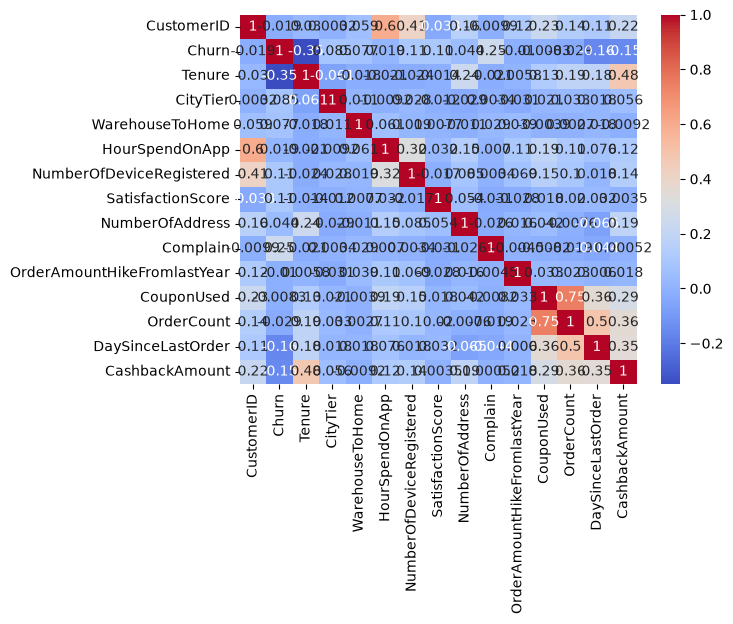

In [4]:
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm')
plt.show()

step2 : data cleaning

In [5]:
print(df.isnull().sum())

CustomerID                       0
Churn                            0
Tenure                         264
PreferredLoginDevice             0
CityTier                         0
WarehouseToHome                251
PreferredPaymentMode             0
Gender                           0
HourSpendOnApp                 255
NumberOfDeviceRegistered         0
PreferedOrderCat                 0
SatisfactionScore                0
MaritalStatus                    0
NumberOfAddress                  0
Complain                         0
OrderAmountHikeFromlastYear    265
CouponUsed                     256
OrderCount                     258
DaySinceLastOrder              307
CashbackAmount                   0
dtype: int64


In [6]:
num_cols = df.select_dtypes('number').columns
df[num_cols] = df[num_cols].fillna(df[num_cols].median())
df.drop_duplicates(inplace=True)
print("Missing values left:", df.isnull().sum().sum())

Missing values left: 0


step3 : key insights

In [7]:
print("Churn rate %:", round(df['Churn'].mean() * 100, 1))
print(df.groupby('Churn')['Tenure'].mean().round(1))
print((df.groupby('Complain')['Churn'].mean() * 100).round(1))
print((df.groupby('PreferedOrderCat')['Churn'].mean() * 100).round(1))

Churn rate %: 16.8
Churn
0    11.4
1     3.9
Name: Tenure, dtype: float64
Complain
0    10.9
1    31.7
Name: Churn, dtype: float64
PreferedOrderCat
Fashion               15.5
Grocery                4.9
Laptop & Accessory    10.2
Mobile                27.2
Mobile Phone          27.5
Others                 7.6
Name: Churn, dtype: float64


insights : 
- Churn rate is **16.8%**, so about 1 in 6 customers leaves.
- Churned customers have an average tenure of **3.9 months**, retained customers have **11.4 months**. New customers leave more.
- Customers who complained churn at **31.7%**, those who did not complain churn at **10.9%**.
- Grocery has the lowest churn (**4.9%**) and Mobile has the highest (about **27%**).

step4 : visualization

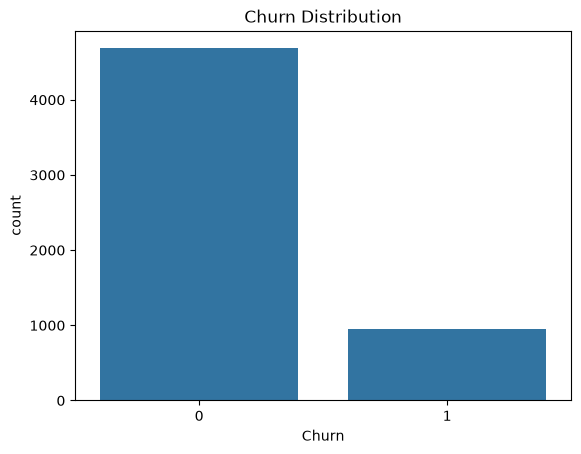

In [9]:
sns.countplot(x='Churn', data=df)
plt.title("Churn Distribution")
plt.show()

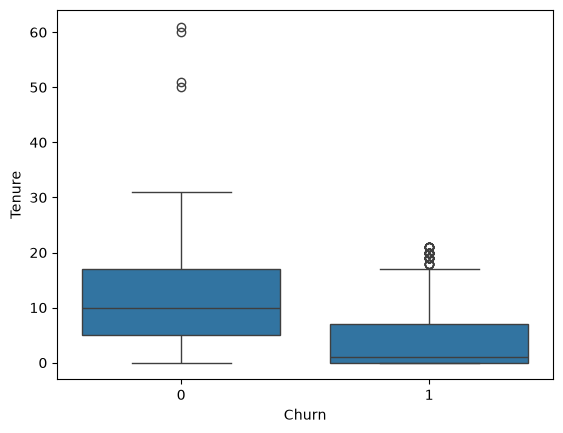

In [10]:
sns.boxplot(x='Churn', y='Tenure', data=df)
plt.show()

step5 : logistic regression

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

X = df[['Tenure', 'CashbackAmount', 'Complain']]
y = df['Churn']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
model = LogisticRegression(max_iter=1000, class_weight='balanced')
model.fit(X_train, y_train)
preds = model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, preds))
print(classification_report(y_test, preds))


Accuracy: 0.7175843694493783
              precision    recall  f1-score   support

           0       0.95      0.70      0.80       936
           1       0.35      0.80      0.49       190

    accuracy                           0.72      1126
   macro avg       0.65      0.75      0.65      1126
weighted avg       0.85      0.72      0.75      1126



Note:Only about 17% of customers churn, so accuracy alone is misleading. I used class_weight='balanced' so the model catches more churners. The model catches 80% of customers who actually churn (recall), but only 35% of flagged customers really churn (precision).